# V1 groundwork: why the val Funk chroma is dominated by G#/A

V0 finding 3 left one question open: in `04_Funk2-119-G`, a G-minor take, the chroma is dominated by
**G# and A**, which do not belong to the progression. Is that a **tuning** problem (the audio sits
between two pitch classes), a **template** problem (the chords are played in voicings a triad
template cannot read), or something else?

**Validation only.** Every take here is from the val split. Test is scored once and never inspected,
so `val_take()` below refuses a test take. Nothing here changes V0 code or results: the notebook only
imports the committed `chordtracker` modules.

GuitarSet gives us something most chord datasets do not: a **transcription of every note** the
player played (`note_midi`, one annotation per string). So we can compare what the chroma *says*
with what was *played*.

Running everything takes a few minutes (the val-wide cells reload all 60 takes).

In [1]:
import json

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from chordtracker import decode, emission, evaluate, features, templates
from chordtracker.data.data import ChordAnnotation, load_split
from chordtracker.paths import DATA_DIR, REPO_ROOT, SPLITS_DIR

CFG = yaml.safe_load(open(REPO_ROOT / "configs" / "v0.yaml"))
SPLIT = load_split(SPLITS_DIR / "guitarset.json")
VAL = SPLIT["val"]
GUITARSET = DATA_DIR / "guitarset"
PC = templates.PITCH_CLASSES
P_SELF = 0.95                               # chosen on val in V0

EMISSION = emission.TemplateEmission.from_config(CFG)
LABELS = EMISSION.labels
FRAMEWISE, VITERBI = decode.FramewiseDecoder(), decode.ViterbiDecoder(P_SELF)


def val_take(song_id: str) -> str:
    # the leakage rule in code: this notebook only ever looks at val takes
    if song_id not in VAL:
        raise ValueError(f"{song_id} is not a val take; test takes are never inspected")
    return song_id


def audio_path(song_id):
    return GUITARSET / "audio_mono-mic_comp" / f"{val_take(song_id)}_mic.wav"


def jams_path(song_id):
    return GUITARSET / "annotation" / f"{val_take(song_id)}.jams"


def played_notes(song_id) -> np.ndarray:
    # (n_notes, 3): onset s, duration s, MIDI pitch as a float (52.07 = E3 played 7 cents sharp)
    with open(jams_path(song_id)) as f:
        annotations = json.load(f)["annotations"]
    return np.array([(note["time"], note["duration"], note["value"])
                     for a in annotations if a["namespace"] == "note_midi" for note in a["data"]])


def note_chroma(song_id, frame_times) -> np.ndarray:
    # (12, n_frames) binary chroma of the transcription: 1 where a note of that pitch class sounds
    chroma = np.zeros((12, len(frame_times)))
    for onset, duration, pitch in played_notes(song_id):
        chroma[int(round(pitch)) % 12, (frame_times >= onset) & (frame_times < onset + duration)] = 1
    return chroma


def score_chroma(chroma, take) -> dict:
    # same templates, softmax and decoders as V0, scored with the V0 evaluation code
    posteriors = EMISSION.posteriors(chroma[:, :len(take["times"])])
    out = {}
    for name, decoder in [("framewise", FRAMEWISE), ("viterbi", VITERBI)]:
        estimate = evaluate.path_to_annotation(decoder.decode(posteriors), LABELS, take["times"], take["duration"])
        out[name] = evaluate.score(take["reference"], estimate)
    return out


def load_take(song_id) -> dict:
    # everything V0 computes for one take, plus the raw CQT that chroma_cqt folds into 12 bins
    y, sr = features.load_audio(audio_path(song_id), CFG)
    tuning = librosa.estimate_tuning(y=y, sr=sr, bins_per_octave=36)   # what chroma_cqt does with tuning: null
    chroma = features.chroma(y, sr, CFG)
    reference = ChordAnnotation.from_jams(jams_path(song_id), 0)        # lead sheet, same as the .lab
    return {"song_id": song_id, "y": y, "sr": sr, "tuning": tuning, "chroma": chroma,
            "times": librosa.frames_to_time(np.arange(chroma.shape[1]), sr=sr, hop_length=CFG["features"]["hop_length"]),
            "reference": reference, "duration": float(reference.intervals[-1, 1])}

## 1. Reproduce V0 on the val Funk takes

Before explaining a number, check that we get the same number. The 12 val Funk takes are six players
(`00`–`05`) × two progressions (`Funk2-108-Eb`, `Funk2-119-G`). The scores must equal
`results/v0/val/per_song.csv` (for `04_Funk2-119-G`: 11.2 % framewise, 2.6 % Viterbi).

In [2]:
FUNK = [t for t in VAL if "Funk" in t]
funk = {t: load_take(t) for t in FUNK}

v0_csv = pd.read_csv(REPO_ROOT / "results" / "v0" / "val" / "per_song.csv")
v0_csv = v0_csv[v0_csv.system.isin(["framewise", str(P_SELF)])].pivot(index="song_id", columns="system", values="wcsr")

rows = []
for t, take in funk.items():
    s = score_chroma(take["chroma"], take)
    rows.append({"take": t, "framewise %": 100 * s["framewise"].wcsr, "viterbi %": 100 * s["viterbi"].wcsr,
                 "results/v0 framewise %": 100 * v0_csv.loc[t, "framewise"],
                 "results/v0 viterbi %": 100 * v0_csv.loc[t, str(P_SELF)]})
pd.DataFrame(rows).set_index("take").round(1)

,framewise %,viterbi %,results/v0 framewise %,results/v0 viterbi %
take,,,,
00_Funk2-108-Eb_comp,34.3,40.3,34.3,40.3
00_Funk2-119-G_comp,51.1,75.6,51.1,75.6
01_Funk2-108-Eb_comp,17.5,20.4,17.5,20.4
01_Funk2-119-G_comp,16.1,22.7,16.1,22.7
02_Funk2-108-Eb_comp,31.6,30.5,31.6,30.5
02_Funk2-119-G_comp,41.3,55.4,41.3,55.4
03_Funk2-108-Eb_comp,23.3,30.1,23.3,30.1
03_Funk2-119-G_comp,16.7,20.2,16.7,20.2
04_Funk2-108-Eb_comp,5.8,12.8,5.8,12.8


## 2. Is it tuning?

A chroma bin covers one semitone = 100 cents. Energy only spills into the *neighbouring* pitch class
when the instrument is off by a large part of that, around ±50 cents. Two independent measurements:

- **From the notes.** `note_midi` stores pitch as a float, so `pitch − round(pitch)` is how far each
  played note is from A440 equal temperament. The median over the take is the player's tuning, in cents.
- **From librosa.** `chroma_cqt(tuning=None)` estimates the tuning per file; V0 uses that. It is
  returned in fractions of a 1/36-octave bin, so cents = `tuning × 100 / 3`.

If the two agree and both are small, the chroma is folded at the right place and tuning is ruled out.

In [3]:
rows = []
for t, take in funk.items():
    pitches = played_notes(t)[:, 2]
    rows.append({"take": t,
                 "notes: median offset (cents)": np.median((pitches - np.round(pitches)) * 100),
                 "librosa estimate (cents)": take["tuning"] * 100 / 3})
pd.DataFrame(rows).set_index("take").round(1)

,notes: median offset (cents),librosa estimate (cents)
take,,
00_Funk2-108-Eb_comp,8.2,8.7
00_Funk2-119-G_comp,8.8,9.7
01_Funk2-108-Eb_comp,0.1,1.0
01_Funk2-119-G_comp,-1.6,2.3
02_Funk2-108-Eb_comp,9.2,9.7
02_Funk2-119-G_comp,6.4,9.0
03_Funk2-108-Eb_comp,6.6,9.3
03_Funk2-119-G_comp,5.8,9.0
04_Funk2-108-Eb_comp,5.8,5.7


All within about 10 cents of A440, and the two measurements agree. Tuning cannot move energy from G
or A# into G#. Something else is putting it there.

## 3. What the chroma says vs what was played

For each take: the mean chroma (12 numbers, scaled so the largest is 1), next to a pitch-class
histogram of the transcription (each note weighted by its duration, also scaled to max 1). If the
chroma were a faithful picture of the notes, the two bar charts would look alike. The correlation
of the two 12-vectors puts a number on it.

In [4]:
def mean_chroma(take):
    c = take["chroma"].mean(axis=1)
    return c / c.max()


def played_histogram(song_id):
    h = np.zeros(12)
    for _, duration, pitch in played_notes(song_id):
        h[int(round(pitch)) % 12] += duration
    return h / h.max()


rows = []
for t, take in funk.items():
    c, h = mean_chroma(take), played_histogram(t)
    top = lambda v: " ".join(PC[i] for i in np.argsort(-v)[:3])
    rows.append({"take": t, "chroma top 3": top(c), "played top 3": top(h), "correlation": np.corrcoef(c, h)[0, 1]})
pd.DataFrame(rows).set_index("take").round(2)

,chroma top 3,played top 3,correlation
take,,,
00_Funk2-108-Eb_comp,A# F# G#,A# F# G#,0.89
00_Funk2-119-G_comp,G A# A,D C A#,0.63
01_Funk2-108-Eb_comp,G# A G,D# A# F,0.14
01_Funk2-119-G_comp,G# A G,G D A#,0.08
02_Funk2-108-Eb_comp,G# A# F#,D# A# C#,0.48
02_Funk2-119-G_comp,G# A G,D F A#,0.00
03_Funk2-108-Eb_comp,G# A# A,F# A# D#,0.35
03_Funk2-119-G_comp,G# A A#,A# G D#,0.28
04_Funk2-108-Eb_comp,G# A G,A# F# F,0.02


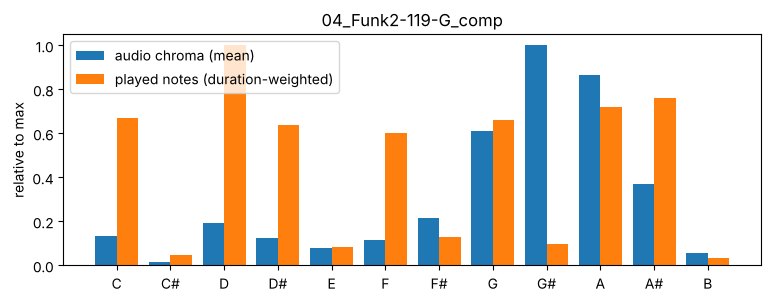

In [5]:
TAKE = "04_Funk2-119-G_comp"
x = np.arange(12)
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(x - 0.2, mean_chroma(funk[TAKE]), 0.4, label="audio chroma (mean)")
ax.bar(x + 0.2, played_histogram(TAKE), 0.4, label="played notes (duration-weighted)")
ax.set_xticks(x, PC); ax.set_ylabel("relative to max"); ax.set_title(TAKE); ax.legend()
plt.show()

In most Funk takes G# is the loudest pitch class in the chroma, in **both** progressions (G minor
and D# minor), while the players hardly play it. The cleanest take, `00_Funk2-108-Eb`, is the
exception, and it is also among the best-scoring Funk takes.

## 4. Where the G# energy comes from

`chroma_cqt` first computes a CQT: 36 bins per octave from C1 (32.7 Hz) over 7 octaves, then adds up
the bins of each pitch class. Looking at the CQT *before* that fold shows which octave and which
exact frequency carries the energy.

In [6]:
FMIN = librosa.note_to_hz("C1")


def cqt_power(take):
    # (252, n_frames) CQT power with the same tuning V0 used, and the centre frequency of each bin
    Q = np.abs(librosa.cqt(take["y"], sr=take["sr"], hop_length=512, fmin=FMIN, n_bins=252,
                           bins_per_octave=36, tuning=take["tuning"])) ** 2
    return Q, librosa.cqt_frequencies(252, fmin=FMIN, bins_per_octave=36, tuning=take["tuning"])


for t in [TAKE, "01_Funk2-108-Eb_comp"]:
    Q, freqs = cqt_power(funk[t])
    loudest = np.argsort(-Q.mean(axis=1))[:3]
    print(t)
    for i in loudest:
        print(f"   {freqs[i]:6.1f} Hz  {librosa.hz_to_note(freqs[i], cents=True):8s}  "
              f"{Q[i].mean() / Q.mean(axis=1).max():.2f} of the loudest bin")
    print(f"   frames whose loudest bin is within 1 bin of {freqs[loudest[0]]:.1f} Hz: "
          f"{np.mean(np.abs(Q.argmax(axis=0) - loudest[0]) <= 1):.0%}")

04_Funk2-119-G_comp
    106.2 Hz  G♯2+39    1.00 of the loudest bin
    104.2 Hz  G♯2+6     0.74 of the loudest bin
    108.3 Hz  A2-27     0.61 of the loudest bin
   frames whose loudest bin is within 1 bin of 106.2 Hz: 61%
01_Funk2-108-Eb_comp
    105.9 Hz  G♯2+34    1.00 of the loudest bin
    108.0 Hz  A2-32     0.76 of the loudest bin
    103.9 Hz  G♯2+1     0.48 of the loudest bin
   frames whose loudest bin is within 1 bin of 105.9 Hz: 71%


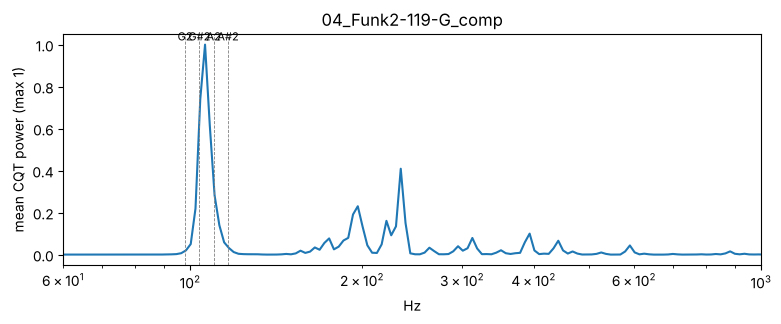

In [7]:
Q, freqs = cqt_power(funk[TAKE])
fig, ax = plt.subplots(figsize=(9, 3))
ax.semilogx(freqs, Q.mean(axis=1) / Q.mean(axis=1).max())
for note in ["G2", "G#2", "A2", "A#2"]:
    ax.axvline(librosa.note_to_hz(note), color="grey", lw=0.6, ls="--")
    ax.text(librosa.note_to_hz(note), 1.02, note, ha="center", fontsize=8)
ax.set_xlim(60, 1000); ax.set_xlabel("Hz"); ax.set_ylabel("mean CQT power (max 1)"); ax.set_title(TAKE)
plt.show()

The energy sits at about **105–108 Hz**, between G#2 (103.8 Hz) and A2 (110 Hz), which is why it
lands in **both** the G# and the A chroma bins. It is at the same frequency in a take in another key,
so it is not a note of the music. That is the range of an acoustic guitar's body (air) resonance,
and funk comping excites it constantly with muted "chuck" strums.

Two checks: (1) is the band loud also **between** notes, when the transcription says nothing is
sounding? (2) how often is a G#2 or A2 actually played?

In [8]:
BAND = (100, 112)   # Hz, read off the spectrum above


def band_share(take):
    # per frame: fraction of all CQT power that lies in BAND
    Q, freqs = cqt_power(take)
    in_band = (freqs > BAND[0]) & (freqs < BAND[1])
    return Q[in_band].sum(axis=0) / Q.sum(axis=0)


rows = []
for t, take in funk.items():
    share, times = band_share(take), take["times"]
    sounding, low_note = np.zeros(len(times), bool), np.zeros(len(times), bool)
    for onset, duration, pitch in played_notes(t):
        frames = (times >= onset) & (times < onset + duration)
        sounding |= frames
        low_note |= frames & (43.5 <= pitch <= 45.5)     # MIDI 44 = G#2, 45 = A2
    rows.append({"take": t, "band share, notes sounding": share[sounding].mean(),
                 "band share, no note": share[~sounding].mean(),
                 "frames with a played G#2/A2": low_note.mean()})
pd.DataFrame(rows).set_index("take").round(2)

,"band share, notes sounding","band share, no note",frames with a played G#2/A2
take,,,
00_Funk2-108-Eb_comp,0.05,0.10,0.04
00_Funk2-119-G_comp,0.08,0.28,0.12
01_Funk2-108-Eb_comp,0.48,0.68,0.00
01_Funk2-119-G_comp,0.54,0.69,0.01
02_Funk2-108-Eb_comp,0.25,0.51,0.11
02_Funk2-119-G_comp,0.38,0.65,0.10
03_Funk2-108-Eb_comp,0.25,0.67,0.00
03_Funk2-119-G_comp,0.22,0.69,0.00
04_Funk2-108-Eb_comp,0.50,0.69,0.02


In `04_Funk2-119-G`, almost half of all the energy is in a 12 Hz band where a note is played in only
about 3 % of the frames, and the share is even higher between notes. After per-frame max
normalization this one band becomes "G# = 1.0" in most frames.

## 5. Is it only Funk? All 60 val takes

Same measurement on every val take, next to its V0 Viterbi score. This cell reloads all val audio.

In [9]:
val_rows = []
for t in VAL:
    take = load_take(t)
    s = score_chroma(take["chroma"], take)
    oracle = score_chroma(note_chroma(t, take["times"]), take)
    pitches = played_notes(t)[:, 2]
    val_rows.append({"take": t, "style": t[3:].split("-")[0].rstrip("0123456789"),
                     "band share": band_share(take).mean(),
                     "tuning error (cents)": take["tuning"] * 100 / 3 - np.median((pitches - np.round(pitches)) * 100),
                     "v0": s["viterbi"], "oracle": oracle["viterbi"]})
val_df = pd.DataFrame(val_rows).set_index("take")
val_df["v0 %"] = [100 * s.wcsr for s in val_df.v0]

print(f"V0 pooled Viterbi WCSR on val: {100 * evaluate.pooled(list(val_df.v0)).wcsr:.1f} %  (report: 61.4 %)")
print(f"librosa tuning within 8 cents of the notes on {(val_df['tuning error (cents)'].abs() <= 8).sum()} of {len(val_df)} takes")
print(f"correlation(band share, V0 Viterbi WCSR) over {len(val_df)} takes: {np.corrcoef(val_df['band share'], val_df['v0 %'])[0, 1]:.2f}")

V0 pooled Viterbi WCSR on val: 61.4 %  (report: 61.4 %)
librosa tuning within 8 cents of the notes on 55 of 60 takes
correlation(band share, V0 Viterbi WCSR) over 60 takes: -0.65


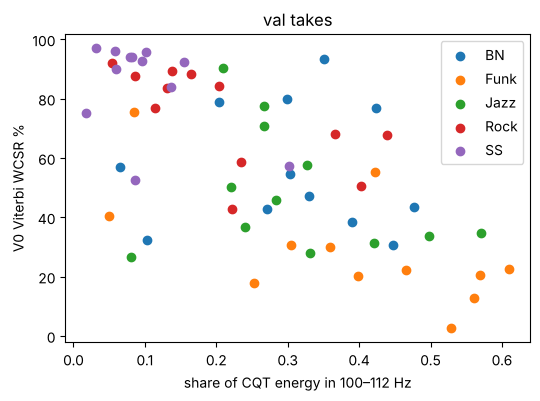

,band_share,v0_viterbi
style,,
BN,0.31,56.11
Funk,0.38,29.07
Jazz,0.31,49.22
Rock,0.21,75.12
SS,0.10,84.99


In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
for style, group in val_df.groupby("style"):
    ax.scatter(group["band share"], group["v0 %"], label=style)
ax.set_xlabel(f"share of CQT energy in {BAND[0]}–{BAND[1]} Hz"); ax.set_ylabel("V0 Viterbi WCSR %")
ax.set_title("val takes"); ax.legend()
plt.show()

val_df.groupby("style").agg(band_share=("band share", "mean"),
                            v0_viterbi=("v0", lambda s: 100 * evaluate.pooled(list(s)).wcsr)).round(2)

The resonance is in every style (least in SS, most in Funk), and the takes with more of it score
lower. It is a property of the mic recordings, not a Funk quirk.

## 6. Would perfect notes be enough? The note oracle

Suppose the resonance were gone and the chroma were *perfect*: exactly the pitch classes the player
played. Replace the chroma by the binary `note_chroma` of the transcription and keep everything else
from V0 (templates, softmax, Viterbi 0.95, scoring). Whatever this "note oracle" still gets wrong is
not the chroma's fault: it is the 25 triad templates.

In [11]:
val_df.groupby("style").agg(v0=("v0", lambda s: 100 * evaluate.pooled(list(s)).wcsr),
                            note_oracle=("oracle", lambda s: 100 * evaluate.pooled(list(s)).wcsr)).round(1)

,v0,note_oracle
style,,
BN,56.1,67.7
Funk,29.1,48.8
Jazz,49.2,53.7
Rock,75.1,82.6
SS,85.0,89.9


In [12]:
print(f"all val: V0 {100 * evaluate.pooled(list(val_df.v0)).wcsr:.1f} %   "
      f"note oracle {100 * evaluate.pooled(list(val_df.oracle)).wcsr:.1f} %")

all val: V0 61.4 %   note oracle 70.8 %


Even perfect notes leave Funk below 50 %. Bar by bar on `04_Funk2-119-G`: the lead-sheet chord, the
chord GuitarSet says was played (annotation 1), the notes that sound in the bar, and the chord the V0
chroma and the note oracle pick most often.

In [13]:
from collections import Counter

take = funk[TAKE]
times = take["times"]
performed = ChordAnnotation.from_jams(jams_path(TAKE), 1)
played = note_chroma(TAKE, times)
v0_path = VITERBI.decode(EMISSION.posteriors(take["chroma"]))
oracle_path = VITERBI.decode(EMISSION.posteriors(played))

rows = []
for (start, end), label in take["reference"]:
    bar = (times >= start) & (times < end)
    counts = played[:, bar].sum(axis=1)
    rows.append({"start s": round(start, 1), "lead sheet": label, "played": performed.at(np.array([start + 0.5]))[0],
                 "notes": " ".join(PC[i] for i in np.argsort(-counts) if counts[i] > 0.15 * counts.max()),
                 "V0 picks": Counter(LABELS[i] for i in v0_path[bar]).most_common(1)[0][0],
                 "oracle picks": Counter(LABELS[i] for i in oracle_path[bar]).most_common(1)[0][0]})
pd.DataFrame(rows).set_index("start s")

,lead sheet,played,notes,V0 picks,oracle picks
start s,,,,,
0.0,C:min,C:min7/1,G D# A# C,G#:min,D#:maj
2.0,F:7,"F:7(7,#9,*5)/1",D# G# A F E,G#:min,G#:maj
4.0,A#:maj,A#:maj7/1,F A A# D,D:min,D:min
6.1,D#:maj,D#:maj7/1,G D# D A# B,G:min,D#:maj
8.1,A:hdim7,A:hdim7/1,G C D# A,C:min,C:min
10.1,D:7,"D:9(#9,*5)/1",C F D F#,F:min,F:maj
12.1,G:min,G:min9(*1)/b7,D A# A F G C#,D:maj,A#:maj
16.1,C:min,C:min/b3,G C D# D,D:maj,C:min
18.2,F:7,F:9/1,D# A G C D F A#,G#:maj,C:min


The voicings are rootless and extended: A#:maj7 played as F A D A# contains D:min exactly, G:min9
over its 7th contains A#:maj, F:9 contains C:min. A triad template cannot separate these without a
bass note or seventh/ninth templates.

## 7. Diagnostic: what removing the resonance would buy

Not a V1 candidate, just the size of the effect. Two ways to take the resonance out of the CQT before
folding it into chroma:

- **notch**: set the 100–112 Hz bins to 0 (the band was read off val, which is allowed for a design
  choice, but it is hand-tuned);
- **minus median**: subtract each CQT bin's median over the take, so anything that is always there
  (a resonance, a hum) drops out, without choosing a band.

In [14]:
def chroma_from_cqt(Q_magnitude, sr):
    return librosa.feature.chroma_cqt(C=Q_magnitude, sr=sr, hop_length=512, threshold=CFG["features"]["threshold"],
                                      norm=np.inf, bins_per_octave=36, n_octaves=7)


fix_rows = []
for t in VAL:
    take = load_take(t)
    Q, freqs = cqt_power(take)
    magnitude = np.sqrt(Q)
    notched = magnitude.copy()
    notched[(freqs > BAND[0]) & (freqs < BAND[1])] = 0
    minus_median = np.maximum(magnitude - np.median(magnitude, axis=1, keepdims=True), 0)
    fix_rows.append({"take": t, "style": val_df.loc[t, "style"], "v0": val_df.loc[t, "v0"],
                     "notch": score_chroma(chroma_from_cqt(notched, take["sr"]), take)["viterbi"],
                     "minus median": score_chroma(chroma_from_cqt(minus_median, take["sr"]), take)["viterbi"]})
fix_df = pd.DataFrame(fix_rows).set_index("take")

pooled_pct = lambda s: 100 * evaluate.pooled(list(s)).wcsr
table = fix_df.groupby("style")[["v0", "notch", "minus median"]].agg(pooled_pct)
table.loc["all"] = [pooled_pct(fix_df[c]) for c in ["v0", "notch", "minus median"]]
for c in ["notch", "minus median"]:
    diff = np.array([a.wcsr - b.wcsr for a, b in zip(fix_df[c], fix_df.v0)])
    print(f"{c}: better on {(diff > 0.005).sum()} takes, worse on {(diff < -0.005).sum()}")
table.round(1)

notch: better on 32 takes, worse on 20
minus median: better on 26 takes, worse on 19


,v0,notch,minus median
style,,,
BN,56.1,56.8,59.1
Funk,29.1,33.2,33.0
Jazz,49.2,44.6,47.8
Rock,75.1,82.2,78.2
SS,85.0,89.4,86.5
all,61.4,64.1,63.5


## Conclusions (val only)

1. **Not tuning.** Players are within about 10 cents of A440, and librosa's estimate agrees with the
   transcription.
2. **A body resonance at about 106 Hz**, between G#2 and A2, fills the G# and A chroma bins. It is in
   every style and the takes with more of it score lower; Funk has the most.
3. **Templates are the bigger limit.** With perfect notes, the V0 templates reach about 71 % on val
   (Funk under 50 %): rootless, extended voicings contain a different triad.
4. Removing the resonance is worth a few points pooled but hurts about a third of the takes, so it
   belongs with the feature work of V2 (log compression, bass chroma). V1 stays as planned:
   beat-synchronous chroma.